# NB_BioAcoustics_1 — Data Audit
**IRA AI Platform — Plant Bioacoustics Module**

**Purpose:** Validate the Dryad dataset structure, count samples per class,
verify sample rates, flag any anomalies. Must run independently.

**Dataset source:** Khait et al. (2023), *Cell 186*, 1328–1336  
https://doi.org/10.5061/dryad.jwstqjqf7

**Expected folder structure (place inside `data/plant_sounds/`):**
```
data/plant_sounds/
    Tomato Dry/        ← drought-stressed tomato
    Tomato Cut/        ← cut tomato
    Tobacco Dry/       ← drought-stressed tobacco
    Tobacco Cut/       ← cut tobacco
    Greenhouse Noises/ ← background noise
    Empty Pot/         ← control (no plant)
```
Each subfolder contains `.wav` files named `id_<plant_id>_sound_<sound_id>.wav`

In [8]:
# ── Imports ──────────────────────────────────────────────────────────────────
import os
import wave
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from collections import defaultdict

print("Libraries loaded.")

Libraries loaded.


In [12]:
# ── Configuration ─────────────────────────────────────────────────────────────
# Update this path to wherever you extracted the Dryad zip
DATA_ROOT = Path("C:/Users/alato/Downloads/files/PlantSounds")

# Class labels and their folder names
CLASS_FOLDERS = {
    "Tomato_Dry":        "Tomato Dry",
    "Tomato_Cut":        "Tomato Cut",
    "Tobacco_Dry":       "Tobacco Dry",
    "Tobacco_Cut":       "Tobacco Cut",
    "Greenhouse_Noise":  "Greenhouse Noises",
    "Empty_Pot":         "Empty Pot",
}

# Expected technical specs (from paper)
EXPECTED_SR       = 500_000   # 500 kHz
EXPECTED_CHANNELS = 1
EXPECTED_FRAMES   = 1001      # 2 ms at 500 kHz = 1000 frames + 1
EXPECTED_SAMPWIDTH = 2        # 16-bit

print(f"Data root: {DATA_ROOT.resolve()}")
print(f"Expected: {EXPECTED_SR} Hz | {EXPECTED_CHANNELS} channel | {EXPECTED_FRAMES} frames | 16-bit")

Data root: C:\Users\alato\Downloads\files\PlantSounds
Expected: 500000 Hz | 1 channel | 1001 frames | 16-bit


## 1. Directory check — are all folders present?

In [13]:
print("Checking folder structure...\n")
missing = []

for label, folder in CLASS_FOLDERS.items():
    path = DATA_ROOT / folder
    status = "OK" if path.exists() else "MISSING"
    if not path.exists():
        missing.append(folder)
    wav_count = len(list(path.glob("*.wav"))) if path.exists() else 0
    print(f"  [{status:7s}] {folder:25s} → {wav_count} .wav files")

if missing:
    print(f"\nWARNING: {len(missing)} folder(s) missing. Update DATA_ROOT or check extraction.")
else:
    print("\nAll folders found.")

Checking folder structure...

  [OK     ] Tomato Dry                → 1622 .wav files
  [OK     ] Tomato Cut                → 660 .wav files
  [OK     ] Tobacco Dry               → 275 .wav files
  [OK     ] Tobacco Cut               → 506 .wav files
  [OK     ] Greenhouse Noises         → 1378 .wav files
  [OK     ] Empty Pot                 → 1036 .wav files

All folders found.


## 2. Full file inventory — read every WAV header

In [14]:
records = []
errors  = []

for label, folder in CLASS_FOLDERS.items():
    folder_path = DATA_ROOT / folder
    if not folder_path.exists():
        continue

    for wav_file in sorted(folder_path.glob("*.wav")):
        # Parse plant_id and sound_id from filename: id_<plant_id>_sound_<sound_id>.wav
        stem = wav_file.stem  # e.g. "id_8_sound_4"
        parts = stem.split("_")
        try:
            plant_id = int(parts[1])
            sound_id = int(parts[3])
        except (IndexError, ValueError):
            plant_id, sound_id = -1, -1

        try:
            with wave.open(str(wav_file), "r") as w:
                sr       = w.getframerate()
                n_frames = w.getnframes()
                channels = w.getnchannels()
                sampwidth= w.getsampwidth()
                duration = n_frames / sr

                # Read signal to compute amplitude stats
                raw  = w.readframes(n_frames)
                data = np.frombuffer(raw, dtype=np.int16).astype(np.float32)

            peak_amp   = np.max(np.abs(data))
            rms_amp    = np.sqrt(np.mean(data**2))
            is_silent  = peak_amp < 10  # threshold for "effectively silent"
            n_nonzero  = np.count_nonzero(data)

            # Flag anomalies
            anomalies = []
            if sr != EXPECTED_SR:             anomalies.append(f"sr={sr}")
            if channels != EXPECTED_CHANNELS: anomalies.append(f"ch={channels}")
            if n_frames != EXPECTED_FRAMES:   anomalies.append(f"frames={n_frames}")
            if sampwidth != EXPECTED_SAMPWIDTH: anomalies.append(f"bits={sampwidth*8}")
            if is_silent:                     anomalies.append("SILENT")

            records.append({
                "class":      label,
                "folder":     folder,
                "filename":   wav_file.name,
                "plant_id":   plant_id,
                "sound_id":   sound_id,
                "sample_rate":sr,
                "n_frames":   n_frames,
                "channels":   channels,
                "bit_depth":  sampwidth * 8,
                "duration_ms":round(duration * 1000, 4),
                "peak_amp":   round(float(peak_amp), 2),
                "rms_amp":    round(float(rms_amp), 2),
                "n_nonzero":  int(n_nonzero),
                "is_silent":  bool(is_silent),
                "anomalies":  ", ".join(anomalies) if anomalies else "none",
            })

        except Exception as e:
            errors.append({"file": str(wav_file), "error": str(e)})

df = pd.DataFrame(records)
print(f"Total files scanned : {len(df)}")
print(f"Read errors         : {len(errors)}")
if errors:
    for e in errors:
        print(f"  ERROR: {e}")
df.head()

Total files scanned : 5477
Read errors         : 0


,class,folder,filename,plant_id,sound_id,sample_rate,n_frames,channels,bit_depth,duration_ms,peak_amp,rms_amp,n_nonzero,is_silent,anomalies
0,Tomato_Dry,Tomato Dry,id_101_sound_1.wav,101,1,500000,1001,1,16,2.002,3489.0,523.35,1001,False,none
1,Tomato_Dry,Tomato Dry,id_101_sound_10.wav,101,10,500000,1001,1,16,2.002,8211.0,864.00,1001,False,none
2,Tomato_Dry,Tomato Dry,id_101_sound_11.wav,101,11,500000,1001,1,16,2.002,5093.0,713.31,1001,False,none
3,Tomato_Dry,Tomato Dry,id_101_sound_12.wav,101,12,500000,1001,1,16,2.002,5871.0,675.97,1001,False,none
4,Tomato_Dry,Tomato Dry,id_101_sound_13.wav,101,13,500000,1001,1,16,2.002,11407.0,825.37,1001,False,none


## 3. Sample counts per class

In [15]:
summary = df.groupby("class").agg(
    n_sounds      = ("filename",  "count"),
    n_plants      = ("plant_id",  "nunique"),
    median_sounds_per_plant = ("sound_id", lambda x: 
                               df.loc[x.index].groupby("plant_id")["sound_id"]
                               .count().median()),
    mean_peak_amp = ("peak_amp",  "mean"),
    mean_rms_amp  = ("rms_amp",   "mean"),
    n_anomalies   = ("anomalies", lambda x: (x != "none").sum()),
    n_silent      = ("is_silent", "sum"),
).reset_index()

summary["mean_peak_amp"] = summary["mean_peak_amp"].round(1)
summary["mean_rms_amp"]  = summary["mean_rms_amp"].round(1)

print("\nPer-class summary:")
print(summary.to_string(index=False))

# Compare with paper's Table S3
print("\nPaper reference counts (Table S3):")
paper = pd.DataFrame([
    {"class": "Tomato_Dry",   "paper_sounds": 1612, "paper_plants": 51, "paper_median": 21},
    {"class": "Tomato_Cut",   "paper_sounds": 631,  "paper_plants": 40, "paper_median": 11.5},
    {"class": "Tobacco_Dry",  "paper_sounds": 209,  "paper_plants": 23, "paper_median": 8},
    {"class": "Tobacco_Cut",  "paper_sounds": 466,  "paper_plants": 19, "paper_median": 24},
])
print(paper.to_string(index=False))


Per-class summary:
           class  n_sounds  n_plants  median_sounds_per_plant  mean_peak_amp  mean_rms_amp  n_anomalies  n_silent
       Empty_Pot      1036         1                   1036.0        12186.2        1118.4            0         0
Greenhouse_Noise      1378         4                    217.0        10217.4        2857.1            0         0
     Tobacco_Cut       506        28                     17.5        11044.2        1114.3            0         0
     Tobacco_Dry       275        35                      7.0        12718.9        1218.9            0         0
      Tomato_Cut       660        43                     11.0        13220.5        1395.6            0         0
      Tomato_Dry      1622        64                      7.5         8484.8         863.8            0         0

Paper reference counts (Table S3):
      class  paper_sounds  paper_plants  paper_median
 Tomato_Dry          1612            51          21.0
 Tomato_Cut           631            4

## 4. Technical spec validation

In [16]:
print("Technical spec validation:")
print(f"  Sample rate  : {df['sample_rate'].unique()} (expected {EXPECTED_SR})")
print(f"  Channels     : {df['channels'].unique()} (expected {EXPECTED_CHANNELS})")
print(f"  Frame counts : {sorted(df['n_frames'].unique())} (expected {EXPECTED_FRAMES})")
print(f"  Bit depth    : {df['bit_depth'].unique()} (expected {EXPECTED_SAMPWIDTH*8})")
print(f"  Duration (ms): {df['duration_ms'].describe()[['min','mean','max']].to_dict()}")

anomalous = df[df["anomalies"] != "none"]
silent    = df[df["is_silent"] == True]

print(f"\nFiles with anomalies : {len(anomalous)}")
print(f"Silent files         : {len(silent)}")

if len(anomalous) > 0:
    print("\nAnomalous files:")
    print(anomalous[["class", "filename", "anomalies"]].to_string(index=False))

if len(silent) > 0:
    print("\nSilent files (peak_amp < 10):")
    print(silent[["class", "filename", "peak_amp"]].to_string(index=False))
else:
    print("\nNo silent files found. All files contain real signal.")

Technical spec validation:
  Sample rate  : [500000] (expected 500000)
  Channels     : [1] (expected 1)
  Frame counts : [np.int64(1001)] (expected 1001)
  Bit depth    : [16] (expected 16)
  Duration (ms): {'min': 2.002, 'mean': 2.0019999999999993, 'max': 2.002}

Files with anomalies : 0
Silent files         : 0

No silent files found. All files contain real signal.


## 5. Amplitude distribution per class

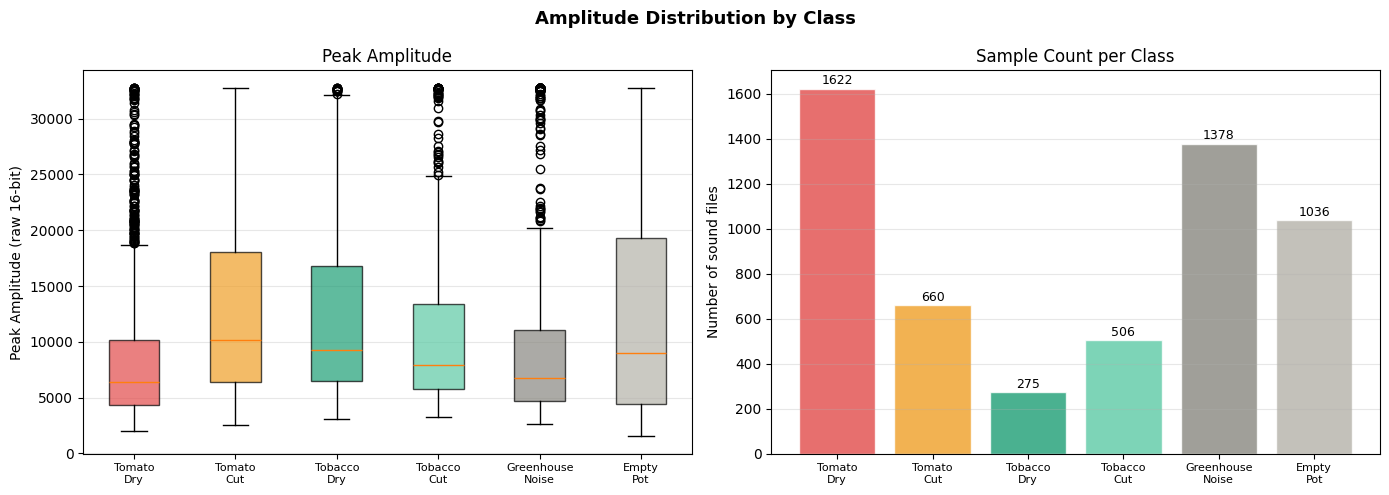

Saved: audit_amplitude_counts.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Amplitude Distribution by Class", fontsize=13, fontweight="bold")

class_order = ["Tomato_Dry", "Tomato_Cut", "Tobacco_Dry", "Tobacco_Cut",
               "Greenhouse_Noise", "Empty_Pot"]
colors = ["#E24B4A", "#EF9F27", "#1D9E75", "#5DCAA5", "#888780", "#B4B2A9"]

# Peak amplitude boxplot
ax = axes[0]
data_grouped = [df[df["class"] == c]["peak_amp"].values for c in class_order]
bp = ax.boxplot(data_grouped, patch_artist=True, notch=False)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xticklabels([c.replace("_", "\n") for c in class_order], fontsize=8)
ax.set_ylabel("Peak Amplitude (raw 16-bit)")
ax.set_title("Peak Amplitude")
ax.grid(axis="y", alpha=0.3)

# Count bar chart
ax2 = axes[1]
counts = [df[df["class"] == c].shape[0] for c in class_order]
bars = ax2.bar(range(len(class_order)), counts, color=colors, alpha=0.8, edgecolor="white")
ax2.set_xticks(range(len(class_order)))
ax2.set_xticklabels([c.replace("_", "\n") for c in class_order], fontsize=8)
ax2.set_ylabel("Number of sound files")
ax2.set_title("Sample Count per Class")
for bar, count in zip(bars, counts):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(count), ha="center", va="bottom", fontsize=9)
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("audit_amplitude_counts.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: audit_amplitude_counts.png")

## 6. Per-plant sound count distribution

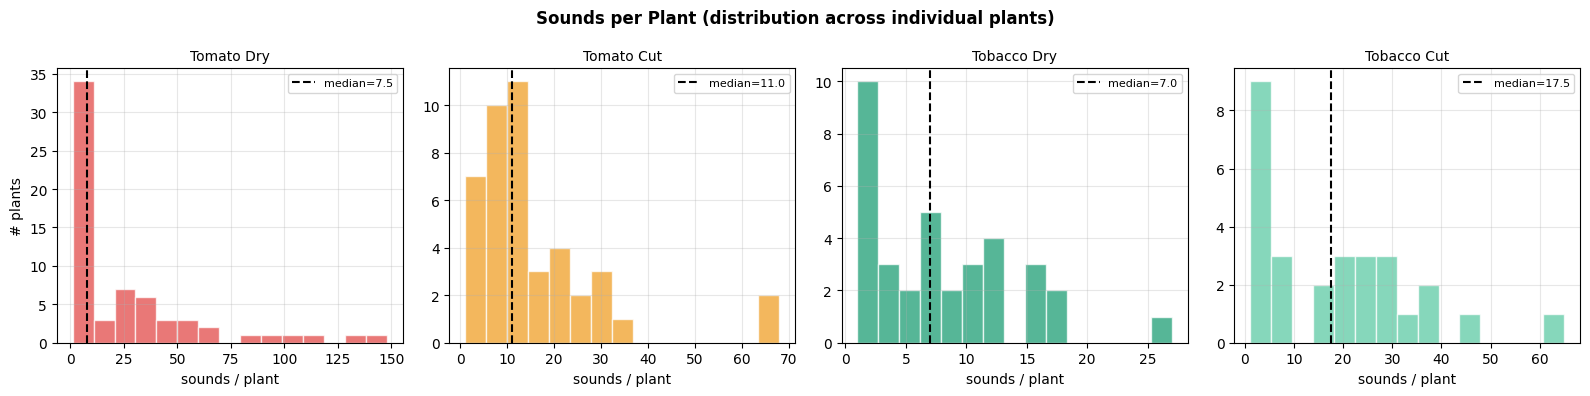

Saved: audit_per_plant_counts.png


In [18]:
plant_classes = ["Tomato_Dry", "Tomato_Cut", "Tobacco_Dry", "Tobacco_Cut"]
plant_colors  = ["#E24B4A", "#EF9F27", "#1D9E75", "#5DCAA5"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle("Sounds per Plant (distribution across individual plants)",
             fontsize=12, fontweight="bold")

for ax, cls, color in zip(axes, plant_classes, plant_colors):
    subset = df[df["class"] == cls]
    per_plant = subset.groupby("plant_id").size()
    ax.hist(per_plant.values, bins=15, color=color, alpha=0.75, edgecolor="white")
    ax.axvline(per_plant.median(), color="black", linestyle="--",
               linewidth=1.5, label=f"median={per_plant.median():.1f}")
    ax.set_title(cls.replace("_", " "), fontsize=10)
    ax.set_xlabel("sounds / plant")
    ax.set_ylabel("# plants" if ax == axes[0] else "")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("audit_per_plant_counts.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: audit_per_plant_counts.png")

## 7. Waveform gallery — 2 random samples per class

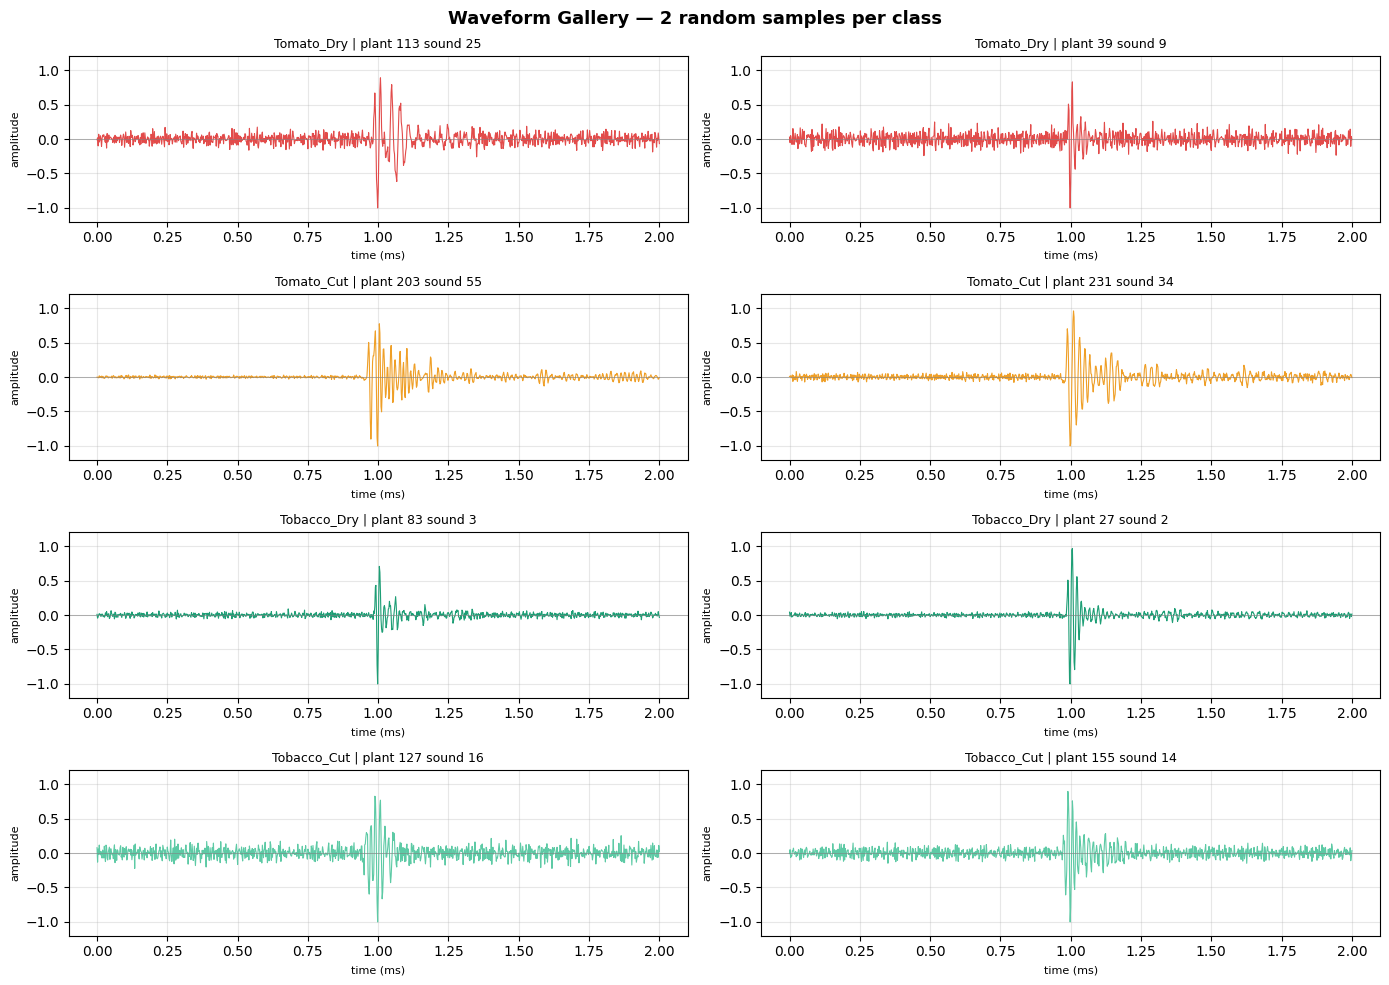

Saved: audit_waveform_gallery.png


In [19]:
np.random.seed(42)
show_classes = ["Tomato_Dry", "Tomato_Cut", "Tobacco_Dry", "Tobacco_Cut"]
show_colors  = ["#E24B4A", "#EF9F27", "#1D9E75", "#5DCAA5"]

fig, axes = plt.subplots(4, 2, figsize=(14, 10))
fig.suptitle("Waveform Gallery — 2 random samples per class",
             fontsize=13, fontweight="bold")

for row_idx, (cls, color) in enumerate(zip(show_classes, show_colors)):
    subset  = df[df["class"] == cls].sample(min(2, len(df[df["class"]==cls])))
    for col_idx, (_, row) in enumerate(subset.iterrows()):
        ax    = axes[row_idx][col_idx]
        fpath = DATA_ROOT / row["folder"] / row["filename"]
        with wave.open(str(fpath), "r") as w:
            raw  = w.readframes(w.getnframes())
            data = np.frombuffer(raw, dtype=np.int16).astype(np.float32)
        data_norm = data / (np.max(np.abs(data)) + 1e-9)
        t = np.arange(len(data)) / EXPECTED_SR * 1000  # ms
        ax.plot(t, data_norm, color=color, linewidth=0.8)
        ax.axhline(0, color="gray", linewidth=0.4)
        ax.set_title(f"{cls} | plant {row['plant_id']} sound {row['sound_id']}",
                     fontsize=9)
        ax.set_xlabel("time (ms)", fontsize=8)
        ax.set_ylabel("amplitude", fontsize=8)
        ax.set_ylim([-1.2, 1.2])
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("audit_waveform_gallery.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: audit_waveform_gallery.png")

## 8. Save master index

In [20]:
output_path = "bioacoustics_master_index.csv"
df.to_csv(output_path, index=False)
print(f"Master index saved to: {output_path}")
print(f"Shape: {df.shape}")

# Final summary
print("\n=== AUDIT SUMMARY ===")
print(f"Total sounds     : {len(df)}")
print(f"Total classes    : {df['class'].nunique()}")
print(f"Total plants     : {df[df['class'].isin(plant_classes)]['plant_id'].nunique()}")
print(f"Silent files     : {df['is_silent'].sum()}")
print(f"Anomalous files  : {(df['anomalies'] != 'none').sum()}")
print(f"\nClass distribution:")
print(df['class'].value_counts().to_string())
print("\nData audit complete. Proceed to NB_BioAcoustics_2_FeatureExtraction.ipynb")

Master index saved to: bioacoustics_master_index.csv
Shape: (5477, 15)

=== AUDIT SUMMARY ===
Total sounds     : 5477
Total classes    : 6
Total plants     : 143
Silent files     : 0
Anomalous files  : 0

Class distribution:
class
Tomato_Dry          1622
Greenhouse_Noise    1378
Empty_Pot           1036
Tomato_Cut           660
Tobacco_Cut          506
Tobacco_Dry          275

Data audit complete. Proceed to NB_BioAcoustics_2_FeatureExtraction.ipynb
